# Grouping Indian Districts by Demographic Profile with K-Means

**Question.** Using four census indicators (literacy rate, gender ratio, share with primary education only, share aged below 29), do India's districts fall into a small number of recognisable profiles? Which states dominate each profile?

**Use case.** Development programmes are often designed state by state. A data-driven grouping shows where districts in *different* states share the same needs, and where one state contains very different district types.

## How K-Means works
K-Means places K centroids and repeats two steps until nothing changes: (1) assign every point to its nearest centroid, and (2) move each centroid to the mean of its points. This minimises the within-cluster sum of squares (WCSS, also called inertia). It assumes roughly spherical, similar-sized clusters on comparable scales, which is why the features are standardised first. K must be chosen by the analyst, here using the elbow in WCSS, the silhouette score and interpretability.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os; os.environ['LOKY_MAX_CPU_COUNT'] = '1'
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.manifold import TSNE
RANDOM_STATE = 0
FIG_DIR, MET_DIR = Path('../outputs/figures'), Path('../outputs/metrics')
FIG_DIR.mkdir(parents=True, exist_ok=True); MET_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid'); plt.rcParams.update({'figure.dpi': 110})

In [2]:
df = pd.read_csv('../data/kmeans_census_data.csv', index_col='district')
df['state'] = df.index.str.split(' - ').str[0].str.title()
FEATS = ['literacy_rate', 'gender_ratio_f_to_1000m', 'percent_primary_ed', 'percent_age_below_29']
print('Districts:', len(df), '| states/UTs:', df['state'].nunique(), '| missing:', int(df[FEATS].isna().sum().sum()))
display(df[FEATS].describe().T.round(3))
display(df[FEATS].corr().round(2))

Districts: 640 | states/UTs: 35 | missing: 0


,count,mean,std,min,25%,50%,75%,max
literacy_rate,640.0,0.625,0.105,0.29,0.55,0.62,0.702,0.89
gender_ratio_f_to_1000m,640.0,945.433,60.607,534.00,906.00,949.00,983.000,1184.00
percent_primary_ed,640.0,0.170,0.039,0.06,0.14,0.16,0.190,0.32
percent_age_below_29,640.0,0.590,0.056,0.40,0.55,0.60,0.630,0.74


,literacy_rate,gender_ratio_f_to_1000m,percent_primary_ed,percent_age_below_29
literacy_rate,1.00,0.15,0.30,-0.71
gender_ratio_f_to_1000m,0.15,1.00,0.19,-0.36
percent_primary_ed,0.30,0.19,1.00,-0.09
percent_age_below_29,-0.71,-0.36,-0.09,1.00


**Observation:** 640 districts across 35 states and union territories, with no missing values. Literacy ranges from 29% to 89%, and the gender ratio from 534 to 1,184 women per 1,000 men. Literacy and the young-population share are strongly negatively correlated (r = -0.71): less literate districts are also younger.

,K,WCSS,Silhouette,Smallest cluster,WCSS drop from K-1
0,2,1719.902,0.300,301,NaN
1,3,1413.102,0.275,139,306.800
2,4,1149.812,0.280,114,263.290
3,5,1028.471,0.247,94,121.341
4,6,922.303,0.236,85,106.168
5,7,846.731,0.234,35,75.572
6,8,785.804,0.226,35,60.927
7,9,743.217,0.216,41,42.587
8,10,701.036,0.222,7,42.182


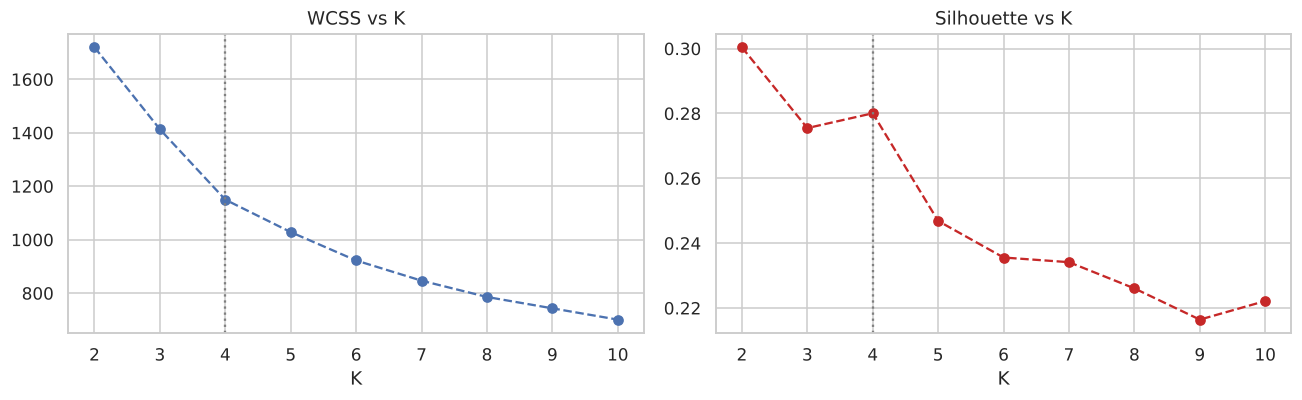

In [3]:
scaler = StandardScaler(); Z = scaler.fit_transform(df[FEATS])
rows = []
for k in range(2, 11):
    m = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(Z)
    rows.append({'K': k, 'WCSS': m.inertia_, 'Silhouette': silhouette_score(Z, m.labels_), 'Smallest cluster': np.bincount(m.labels_).min()})
k_tbl = pd.DataFrame(rows); k_tbl['WCSS drop from K-1'] = -k_tbl['WCSS'].diff()
display(k_tbl.round(3)); k_tbl.round(4).to_csv(MET_DIR / 'k_selection.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(k_tbl.K, k_tbl.WCSS, 'o--'); axes[0].set_title('WCSS vs K'); axes[0].set_xlabel('K')
axes[1].plot(k_tbl.K, k_tbl.Silhouette, 'o--', color='#C62828'); axes[1].set_title('Silhouette vs K'); axes[1].set_xlabel('K')
for ax in axes: ax.axvline(4, color='grey', ls=':')
plt.tight_layout(); plt.savefig(FIG_DIR / 'k_selection.png', bbox_inches='tight'); plt.show()

**Observation:** The silhouette score is highest at K = 2 (0.300), dips at K = 3 (0.275), and recovers slightly at K = 4 (0.280) before declining steadily. WCSS drops sharply up to K = 4 (by 307 and then 263) and much less afterwards (121). K = 4 is chosen: it is the last large elbow step, it has a local silhouette peak, and it keeps a reasonable smallest cluster (114 districts).

In [4]:
K = 4
km = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10).fit(Z)
df['cluster'] = km.labels_
cent = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=FEATS)
cent['districts'] = np.bincount(km.labels_)
z_cent = pd.DataFrame(km.cluster_centers_, columns=FEATS)
def name(r):
    if r['literacy_rate'] > 0.5 and r['gender_ratio_f_to_1000m'] > 0.5: return 'High literacy, female-majority'
    if r['literacy_rate'] > 0.3: return 'High literacy, male-skewed'
    if r['percent_age_below_29'] > 0.5: return 'Low literacy, young'
    return 'Average literacy, high primary-only share'
cent['profile'] = [name(r) for _, r in z_cent.iterrows()]
df['profile'] = df['cluster'].map(cent['profile'])
display(cent.set_index('profile').round(3))
display(z_cent.assign(profile=cent['profile']).set_index('profile').round(2))
cent.round(4).to_csv(MET_DIR / 'cluster_profiles.csv', index=False)

,literacy_rate,gender_ratio_f_to_1000m,percent_primary_ed,percent_age_below_29,districts
profile,,,,,
"Low literacy, young",0.526,938.479,0.148,0.634,242
"High literacy, female-majority",0.711,1002.923,0.172,0.522,156
"High literacy, male-skewed",0.681,876.211,0.150,0.576,114
"Average literacy, high primary-only share",0.655,950.164,0.226,0.599,128


,literacy_rate,gender_ratio_f_to_1000m,percent_primary_ed,percent_age_below_29
profile,,,,
"Low literacy, young",-0.94,-0.11,-0.55,0.81
"High literacy, female-majority",0.82,0.95,0.05,-1.21
"High literacy, male-skewed",0.54,-1.14,-0.50,-0.24
"Average literacy, high primary-only share",0.29,0.08,1.42,0.16


**Observation:** The four profiles are distinct. **Low literacy, young** (242 districts): 53% literacy, 63% under 29. **High literacy, female-majority** (156): 71% literacy, 1,003 women per 1,000 men, the oldest population. **High literacy, male-skewed** (114): 68% literacy but only 876 women per 1,000 men. **Average literacy, high primary-only share** (128): 23% with primary education only, against 15-17% elsewhere.

In [5]:
comp = pd.crosstab(df['state'], df['profile'])
top_states = {p: comp[p].sort_values(ascending=False).head(5).to_dict() for p in comp.columns}
for p, d in top_states.items(): print(f'{p}: {d}')
split_states = comp[(comp > 0).sum(axis=1) >= 3].assign(total=lambda d: d.sum(axis=1)).sort_values('total', ascending=False).head(8)
print('\nStates whose districts span 3 or more profiles:'); display(split_states)
comp.to_csv(MET_DIR / 'state_by_profile.csv')

Average literacy, high primary-only share: {'Gujarat': 21, 'Assam': 18, 'Karnataka': 12, 'Uttar Pradesh': 12, 'Orissa': 11}
High literacy, female-majority: {'Tamil Nadu': 32, 'Andhra Pradesh': 19, 'Karnataka': 15, 'Maharashtra': 15, 'Kerala': 14}
High literacy, male-skewed: {'Haryana': 19, 'Punjab': 18, 'Uttar Pradesh': 13, 'Maharashtra': 12, 'Madhya Pradesh': 10}
Low literacy, young: {'Uttar Pradesh': 46, 'Madhya Pradesh': 38, 'Bihar': 35, 'Rajasthan': 30, 'Jharkhand': 17}

States whose districts span 3 or more profiles:


profile,"Average literacy, high primary-only share","High literacy, female-majority","High literacy, male-skewed","Low literacy, young",total
state,,,,,
Uttar Pradesh,12,0,13,46,71
Madhya Pradesh,0,2,10,38,50
Maharashtra,7,15,12,1,35
Orissa,11,10,0,9,30
Karnataka,12,15,1,2,30
Assam,18,4,0,5,27
Gujarat,21,2,2,1,26
Jharkhand,6,0,1,17,24


**Observation:** The profiles follow well-known regional patterns without being given any location data. Low-literacy, young districts are concentrated in Uttar Pradesh, Madhya Pradesh, Bihar and Rajasthan. Female-majority, high-literacy districts are mostly in Tamil Nadu, Andhra Pradesh, Karnataka, Maharashtra and Kerala. Male-skewed districts lead in Haryana and Punjab. Several large states span three or four profiles: Uttar Pradesh, Maharashtra, Odisha (listed as Orissa), Karnataka and Assam. For those states, a single state-wide programme would not suit every district.

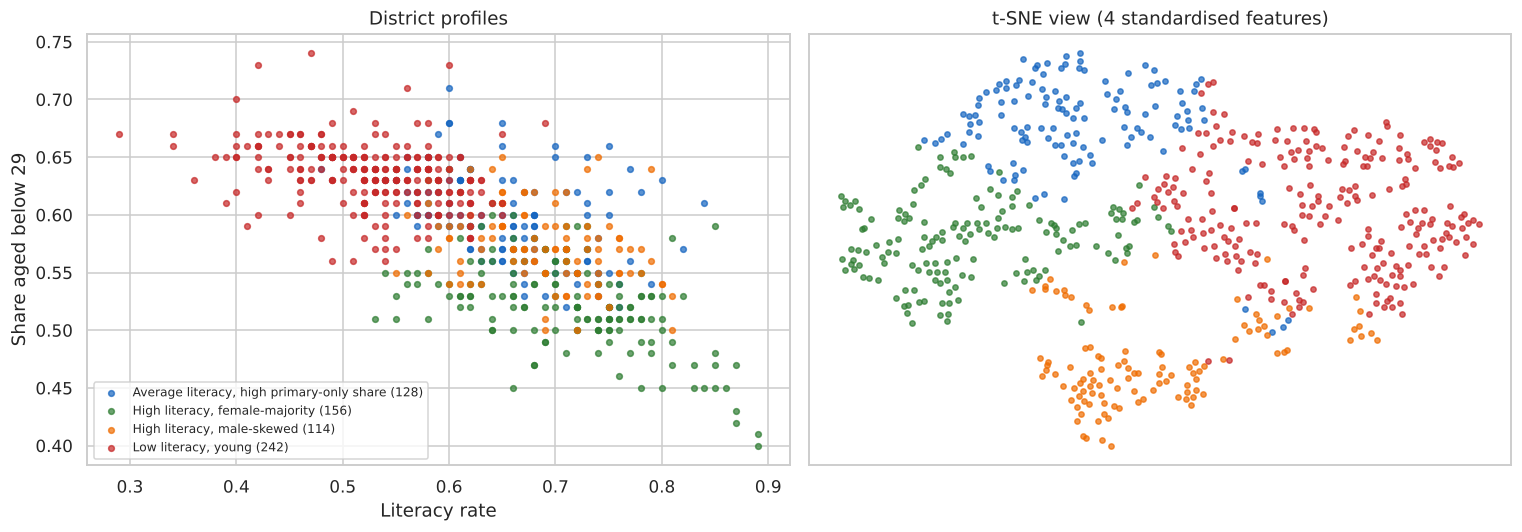

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pal = dict(zip(sorted(df['profile'].unique()), ['#1565C0', '#2E7D32', '#EF6C00', '#C62828']))
for p, sub in df.groupby('profile'):
    axes[0].scatter(sub['literacy_rate'], sub['percent_age_below_29'], s=14, alpha=0.7, color=pal[p], label=f'{p} ({len(sub)})')
axes[0].set_xlabel('Literacy rate'); axes[0].set_ylabel('Share aged below 29'); axes[0].set_title('District profiles'); axes[0].legend(fontsize=8)
emb = TSNE(n_components=2, random_state=42, init='pca', learning_rate='auto').fit_transform(Z)
for p in pal:
    m = (df['profile'] == p).values; axes[1].scatter(emb[m, 0], emb[m, 1], s=12, alpha=0.7, color=pal[p], label=p)
axes[1].set_title('t-SNE view (4 standardised features)'); axes[1].set_xticks([]); axes[1].set_yticks([])
plt.tight_layout(); plt.savefig(FIG_DIR / 'district_profiles.png', bbox_inches='tight'); plt.show()

**Observation:** Literacy against young-population share separates the low-literacy group cleanly. The two high-literacy groups overlap on this view and are separated mainly by gender ratio. The t-SNE view confirms four coherent regions with soft boundaries, consistent with a modest silhouette of 0.28.

In [7]:
ari = [adjusted_rand_score(km.labels_, KMeans(n_clusters=K, random_state=s, n_init=10).fit(Z).labels_) for s in range(1, 21)]
print(f'Stability across 20 seeds - ARI mean {np.mean(ari):.3f}, min {np.min(ari):.3f}')
print(f'Silhouette at K = 4: {silhouette_score(Z, km.labels_):.3f}')

Stability across 20 seeds - ARI mean 0.995, min 0.975
Silhouette at K = 4: 0.280


**Observation:** The partition is very stable across 20 random initialisations (mean ARI 0.995, minimum 0.975), even though the silhouette is only moderate. The profiles are reproducible, but the boundaries between them are gradual rather than sharp.

# Conclusion

| Profile | Districts | Literacy | Women per 1,000 men | Primary-only education | Aged < 29 | Leading states |
|---|---|---|---|---|---|---|
| Low literacy, young | 242 | 53% | 938 | 15% | 63% | UP, MP, Bihar, Rajasthan |
| High literacy, female-majority | 156 | 71% | 1,003 | 17% | 52% | Tamil Nadu, Andhra Pradesh, Karnataka, Kerala |
| High literacy, male-skewed | 114 | 68% | 876 | 15% | 58% | Haryana, Punjab, UP, Maharashtra |
| Average literacy, high primary-only share | 128 | 66% | 950 | 23% | 60% | Gujarat, Assam, Karnataka |

**Findings**
1. Four indicators are enough to recover India's main regional demographic patterns without any geographic input.
2. Several large states contain three or four distinct district types, which supports district-level rather than state-level targeting.
3. The clusters are stable (ARI ≥ 0.975) but only moderately separated (silhouette 0.28): the profiles are useful summaries of a continuum, not sharply distinct groups.

**Limitations:** Four indicators from a single census snapshot (state names follow the census era, e.g. Orissa). Districts are not weighted by population. K-Means assumes roughly spherical clusters of similar size.